In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from solver import solve_vlasov_poisson, plot_vp_solution
from optimizer_3 import optimizer, scan_2d

In [6]:
x_res = 2**7
v_res = 2**7
alpha = 1e-3
beta = 0.2
v_bar = 2.4

x = np.linspace(0.0, 2.0 * np.pi / beta, x_res)
v = np.linspace(-6.0, 6.0, v_res)
X, V = np.meshgrid(x, v)

f_eq = (np.exp(-(V - v_bar)**2 / 2.0) + np.exp(-(V + v_bar)**2 / 2.0)) / (2.0 * np.sqrt(2.0 * np.pi))
f0 = (1.0 + alpha * np.cos(beta * X)) * f_eq
f_desired = f_eq.copy()
T = 40.0
dt = 0.1
t_res = int(round(T / dt))

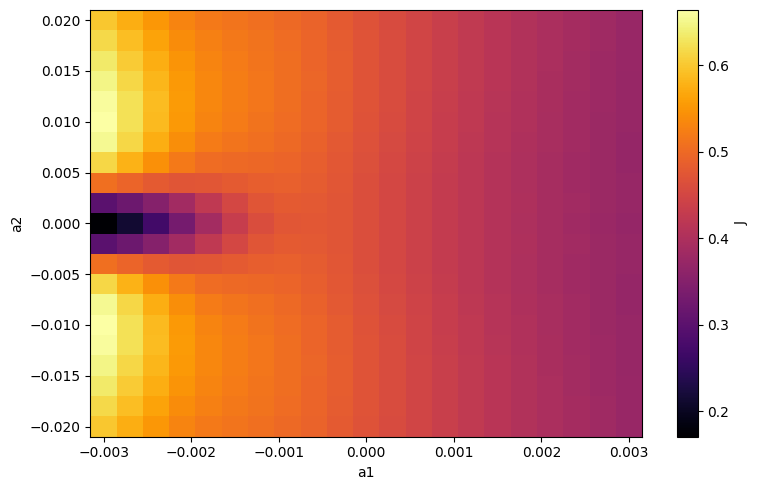

In [7]:
modes = np.array([1, 2])
a_initial_guess = np.array([-0.00200000, 0.01500000])

a1_min = -0.003
a1_max = 0.003
a2_min = -0.02
a2_max = 0.02
a1_step = 0.0003
a2_step = 0.002

scan_2d(
    f_desired, a1_min, a1_max, a2_min, a2_max, a1_step, a2_step,
    modes, f0, x, v, T, t_res,
)

In [8]:
coefficients, H, f_final = optimizer(
    f_desired, a_initial_guess, modes, f0, x, v, T, t_res,
    tolerance=1e-3, learning_rate=0.15, max_iter=5000,
)
print("Final Coefficients:", coefficients)

Iteration 0/5000
Cost function: J(f[H(a1, ..., ak)]) = 0.5436357339753588
a1, ..., ak = [-0.002  0.015]
gradient norm = 65.71505744912962
 
Iteration 1/5000
Cost function: J(f[H(a1, ..., ak)]) = 1.9438693515496408
a1, ..., ak = [9.84807192 0.39133854]
gradient norm = 0.06326372997765986
 
Iteration 2/5000
Cost function: J(f[H(a1, ..., ak)]) = 1.943267855197926
a1, ..., ak = [9.83861243 0.39058364]
gradient norm = 0.06351034311170616
 
Iteration 3/5000
Cost function: J(f[H(a1, ..., ak)]) = 1.9426616507994487
a1, ..., ak = [9.82911645 0.38982111]
gradient norm = 0.0637642894730628
 
Iteration 4/5000
Cost function: J(f[H(a1, ..., ak)]) = 1.9420511226852666
a1, ..., ak = [9.81958348 0.38904327]
gradient norm = 0.06392409538769483
 
Iteration 5/5000
Cost function: J(f[H(a1, ..., ak)]) = 1.9414367925652756
a1, ..., ak = [9.81002845 0.3882415 ]
gradient norm = 0.06420922078237354
 
Iteration 6/5000
Cost function: J(f[H(a1, ..., ak)]) = 1.9408171336452176
a1, ..., ak = [9.80043148 0.38742799]


KeyboardInterrupt: 

In [ ]:
anim = plot_vp_solution(f0, x, v, T, t_res, H)
HTML(anim.to_jshtml())

In [ ]:
modes = np.array([2, 3])
a_initial_guess = np.array([-0.00300000, 0.02000000])

a1_min = -0.005
a1_max = 0.005
a2_min = -0.05
a2_max = 0.05
a1_step = 0.0005
a2_step = 0.005

scan_2d(
    f_desired, a1_min, a1_max, a2_min, a2_max, a1_step, a2_step,
    modes, f0, x, v, T, t_res,
)

In [ ]:
coefficients, H, f_final = optimizer(
    f_desired, a_initial_guess, modes, f0, x, v, T, t_res,
    tolerance=1e-3, learning_rate=0.15, max_iter=5000,
)
print("Final Coefficients:", coefficients)

In [ ]:
anim = plot_vp_solution(f0, x, v, T, t_res, H)
HTML(anim.to_jshtml())